In [1]:
# may be useful: https://github.com/mdmould/h5ify
# the two sims we're using are SM5_DFD_3_TNG and SM5_LW10_DFD3_TNG

In [2]:
from cosmo_sim_tools.arepo_tools import arepo_package
import sys
sys.path.append('../py_files')
import subhalo_dict
import wandering_bh_catalog as catalog
import h5py
import matplotlib.pyplot as plt
import numpy as np

In [3]:
#Brahma_sim_path = '/orange/lblecha/aklantbhowmick/GAS_BASED_SEED_MODEL_UNIFORM_RUNS/L12p5n512/AREPO/'
#Brahma_sim_name = 'SM5_DFD_3_TNG/'
#Brahma_sim_file = Brahma_sim_path+Brahma_sim_name

In [4]:
# snapshots, redshifts = arepo_package.get_snapshot_redshift_correspondence(Brahma_sim_file)

In [5]:
#subhalo_dict.make_dict(Brahma_sim_file, redshifts, 25, 3) #file, redshift array, chosen snapnum, num subhalos

In [6]:
# %run ../py_files/wandering_bh_catalog.py

In [7]:
#catalog.snapshot_rows(Brahma_sim_file, 8, redshifts[8], max_subhalos=None)

In [8]:
#catalog.snapshot_rows

In [27]:
with h5py.File("/orange/lblecha/pranavsatheesh/wandering_bhs/Data/wandering_bh_SM5_DFD_3_TNG.hdf5") as f:
    is_wandering = f["bh/is_wandering"][:]
    r_kpc = f["bh/r_kpc"] # all radii
    wandering_r_kpc = f["bh/r_kpc"][is_wandering]          # distances of just the wandering BHs
    nonwander_r_kpc = f["bh/r_kpc"][np.invert(is_wandering)]      # distances of all other BHs
    lum = f["bh/lbol_erg_s"] # all lum
    wandering_lum = f["bh/lbol_erg_s"][is_wandering]       # luminosities of wanderers
    nonwander_lum = f["bh/lbol_erg_s"][np.invert(is_wandering)]    # luminosities of others

    snapchoice = 15                                                     # CHANGE SNAPSHOT HERE
    num_halos_in_snap = f["snapshot/n_subhalos"][snapchoice]
    subhalochoice = 10 % num_halos_in_snap                               # CHANGE SUBHALO HERE
    subhalo_start = f["snapshot/subhalo_start"][snapchoice]
    bh_start = f["subhalo/bh_start"][subhalo_start+subhalochoice]
    halfmass_rad = f["subhalo/stellar_halfrad_kpc"][subhalo_start+subhalochoice]
    num_bh_in_halo = f["subhalo/bh_count"][subhalo_start+subhalochoice]
    wandering_in_halo = is_wandering[bh_start:bh_start+num_bh_in_halo]
    r_in_halo = r_kpc[bh_start:bh_start+num_bh_in_halo]
    r_wand_in_halo = r_in_halo[wandering_in_halo]
    r_nonwand_in_halo = r_in_halo[np.invert(wandering_in_halo)]
    lum_in_halo = lum[bh_start:bh_start+num_bh_in_halo]
    lum_wand_in_halo = lum_in_halo[wandering_in_halo]
    lum_nonwand_in_halo = lum_in_halo[np.invert(wandering_in_halo)]

In [28]:
num_halos_in_snap, subhalo_start, bh_start, num_bh_in_halo

(np.int32(49702), np.int64(1647), np.int64(2834), np.int32(11))

In [29]:
wandering_in_halo, r_in_halo, r_wand_in_halo, r_nonwand_in_halo, lum_in_halo, lum_wand_in_halo, lum_nonwand_in_halo

(array([False, False, False, False, False,  True,  True,  True,  True,
         True,  True]),
 array([0.        , 0.9243385 , 1.5161775 , 0.87942797, 1.4672959 ,
        2.5944932 , 2.9879546 , 3.2772796 , 3.1719139 , 4.9906416 ,
        5.5716276 ], dtype=float32),
 array([2.5944932, 2.9879546, 3.2772796, 3.1719139, 4.9906416, 5.5716276],
       dtype=float32),
 array([0.        , 0.9243385 , 1.5161775 , 0.87942797, 1.4672959 ],
       dtype=float32),
 array([1.27629275e+41, 3.24618641e+39, 1.97305383e+40, 4.54430336e+39,
        4.82421485e+39, 1.84742191e+39, 7.62266998e+38, 3.01064305e+39,
        4.74323447e+38, 4.54079819e+39, 3.56361697e+39]),
 array([1.84742191e+39, 7.62266998e+38, 3.01064305e+39, 4.74323447e+38,
        4.54079819e+39, 3.56361697e+39]),
 array([1.27629275e+41, 3.24618641e+39, 1.97305383e+40, 4.54430336e+39,
        4.82421485e+39]))

/tmp/ipykernel_3735144/1531349649.py:2: RuntimeWarning: divide by zero encountered in log10
  plt.scatter(np.log10(r_nonwand_in_halo), np.log10(lum_nonwand_in_halo), label="Nonwandering")


Text(0.5, 1.0, 'Lum vs rad for subhalo 10 of snap 15')

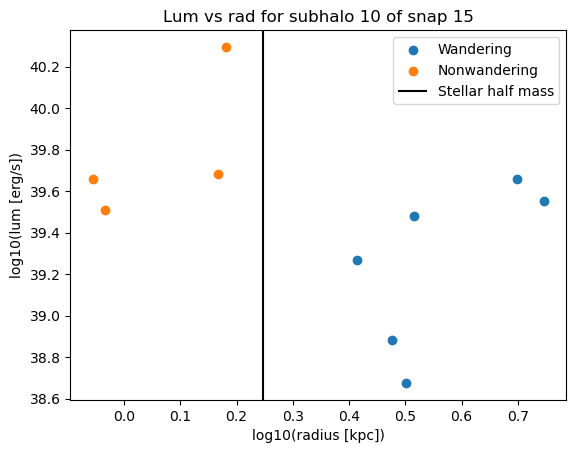

In [30]:
plt.scatter(np.log10(r_wand_in_halo), np.log10(lum_wand_in_halo), label="Wandering")
plt.scatter(np.log10(r_nonwand_in_halo), np.log10(lum_nonwand_in_halo), label="Nonwandering")
plt.axvline(np.log10(halfmass_rad), color="k", label="Stellar half mass")
plt.legend()
plt.xlabel("log10(radius [kpc])")
plt.ylabel("log10(lum [erg/s])")
plt.title(f"Lum vs rad for subhalo {subhalochoice} of snap {snapchoice}") 

In [ ]:
#NOTE: add marking for resolution, find culprit for very low lograds. maybe bh mass >>> rest of halo
# possible other plots: scale radius by sybhalo virial radius, plot diff stellar mass intervals (see ricarte study) 

In [ ]:
is_wandering

In [ ]:
truearr

In [ ]:
wandering_r_kpc

In [ ]:
nonwander_r_kpc

In [ ]:
wandering_lum

In [ ]:
nonwander_lum